# Experiment 5 — Tactical deconfliction between two UAVs

This experiment repeats the two-UAV collision scenario using only tactical deconfliction. Strategic deconfliction is disabled, so both original plans are initially approved. Predicted tracks are then used to detect the encounter and command a vertical maneuver during flight.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    MinimumSeparationTacticalConflictPrediction,
    VerticalManeuverDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    calculate_metrics,
    plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp5"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

UAV A and UAV B follow perpendicular routes and would reach the origin simultaneously at `t = 15 s`. The tracking horizon is six seconds, so the conflict becomes available to the TD only during flight.

In [2]:
SIMULATION_END = 42.0
ORIGINAL_ENCOUNTER_TIME = 15.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0

def create_flight_plans():
    return {
        "UAV A": FlightPlan([
            Waypoint(-100.0, 0.0, 100.0, 0.0),
            Waypoint(100.0, 0.0, 100.0, 30.0),
        ]),
        "UAV B": FlightPlan([
            Waypoint(0.0, -100.0, 100.0, 0.0),
            Waypoint(0.0, 100.0, 100.0, 30.0),
        ]),
    }

## Run the baseline and tactical-deconfliction cases

Both cases use the same tracking algorithm and have strategic deconfliction disabled. In the TD case, the lexicographically last UAV (`UAV B`) receives the vertical maneuver so that both aircraft do not react simultaneously.

In [3]:
CASES = {
    "without_td": "Without tactical deconfliction",
    "with_td": "With tactical deconfliction",
}

def run_case(case_name):
    dataset_path = DATASET_DIRECTORY / f"{case_name}.sqlite"
    tactical_arguments = {}

    if case_name == "with_td":
        tactical_arguments = {
            "tactical_conflict_prediction_algorithm": (
                MinimumSeparationTacticalConflictPrediction(
                    minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
                    maximum_time_difference=0.25,
                )
            ),
            "tactical_deconfliction_algorithm": (
                VerticalManeuverDeconfliction(
                    altitude_offset=60.0,
                    airspace_clearance=10.0,
                    minimum_maneuver_duration=4.0,
                    cooldown=20.0,
                )
            ),
        }

    simulation = Simulation(
        airspace=Airspace(),
        tracking_algorithm=FlightPlanAwareTracking(),
        report_interval=0.5,
        history_window=6,
        prediction_horizon=12,
        prediction_step=0.5,
        flight_update_interval=0.1,
        trajectory_record_interval=0.1,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "tactical_deconfliction_between_uavs",
            "case": case_name,
        },
        overwrite_dataset=True,
        **tactical_arguments,
    )

    for uav_name, flight_plan in create_flight_plans().items():
        simulation.add_uav(
            name=uav_name,
            flight_plan=flight_plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=100.0,
                velocity_time_constant=0.0,
            ),
            guidance_algorithm=WaypointGuidance(
                min_speed=0.0,
                max_speed=15.0,
            ),
            submission_time=0.0 if uav_name == "UAV A" else 0.2,
            waypoint_acceptance_radius=0.5,
        )

    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {case_name: run_case(case_name) for case_name in CASES}
dataset_paths

{'without_td': PosixPath('outputs/output_exp5/datasets/without_td.sqlite'),
 'with_td': PosixPath('outputs/output_exp5/datasets/with_td.sqlite')}

## Metrics

A successful tactical intervention should eliminate collision and loss-of-separation events while producing at least one tactical plan update. The tactical-conflict metric counts detections across prediction cycles, not unique physical encounters.

In [4]:
print(
    f"{'Case':<36} {'tactical conflicts':>19} "
    f"{'interventions':>14} {'LOS':>6} {'collisions':>11} "
    f"{'minimum sep.':>14} {'updates A':>10} {'updates B':>10}"
)
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
    minimum_separation = metrics["minimum_pairwise_separation"]
    minimum_separation_text = (
        "n/a"
        if minimum_separation is None
        else f"{minimum_separation:.2f}"
    )
    print(
        f"{CASES[case_name]:<36} "
        f"{metrics['detected_tactical_conflicts']:19d} "
        f"{metrics['tactical_interventions']:14d} "
        f"{metrics['loss_of_separation_events']:6d} "
        f"{metrics['collision_events']:11d} "
        f"{minimum_separation_text:>14} "
        f"{metrics['per_uav']['UAV A']['updates']:10d} "
        f"{metrics['per_uav']['UAV B']['updates']:10d}"
    )

Case                                  tactical conflicts  interventions    LOS  collisions   minimum sep.  updates A  updates B
Without tactical deconfliction                         0              0      1           1           0.47          0          0
With tactical deconfliction                            1              1      0           0          47.37          0          1


## Encounter-time figures

The figures use `plot_dataset()` in 3D and show the latest predicted tracks at the original encounter time.

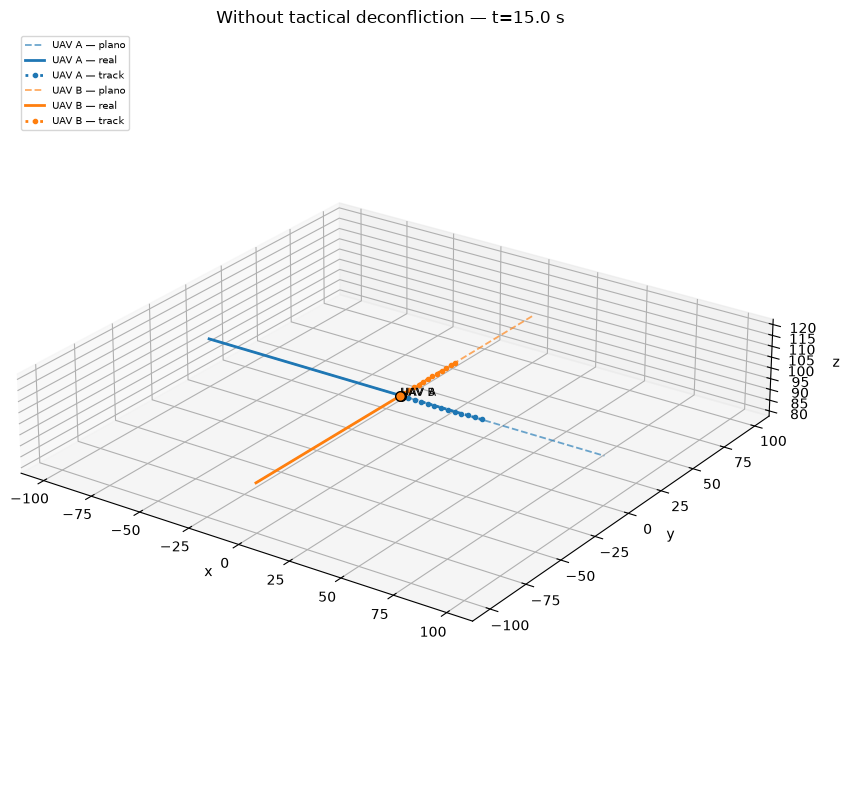

Saved: outputs/output_exp5/without_td.png


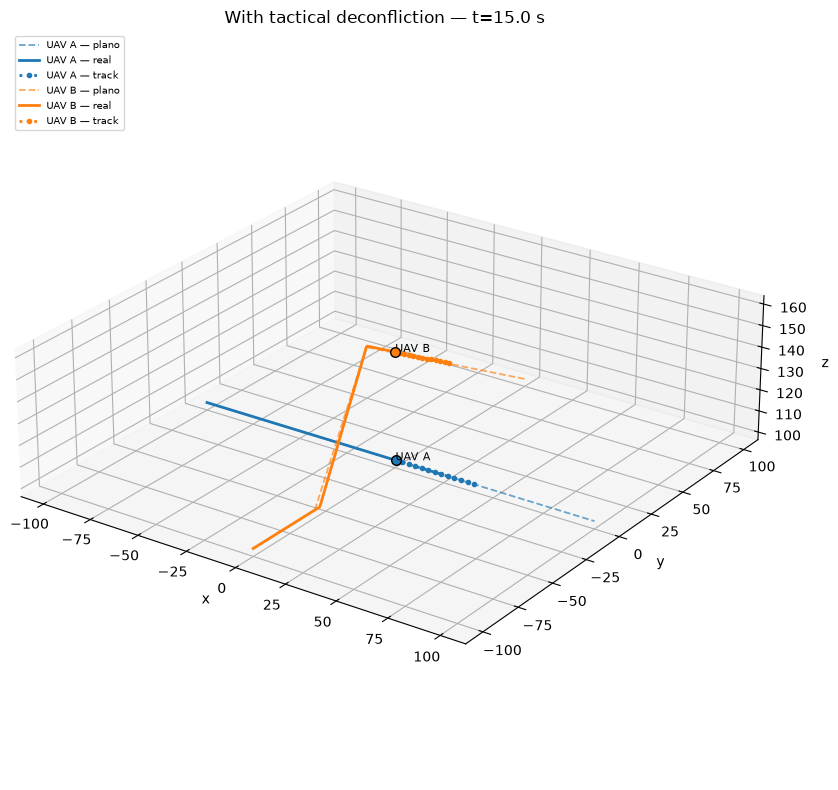

Saved: outputs/output_exp5/with_td.png


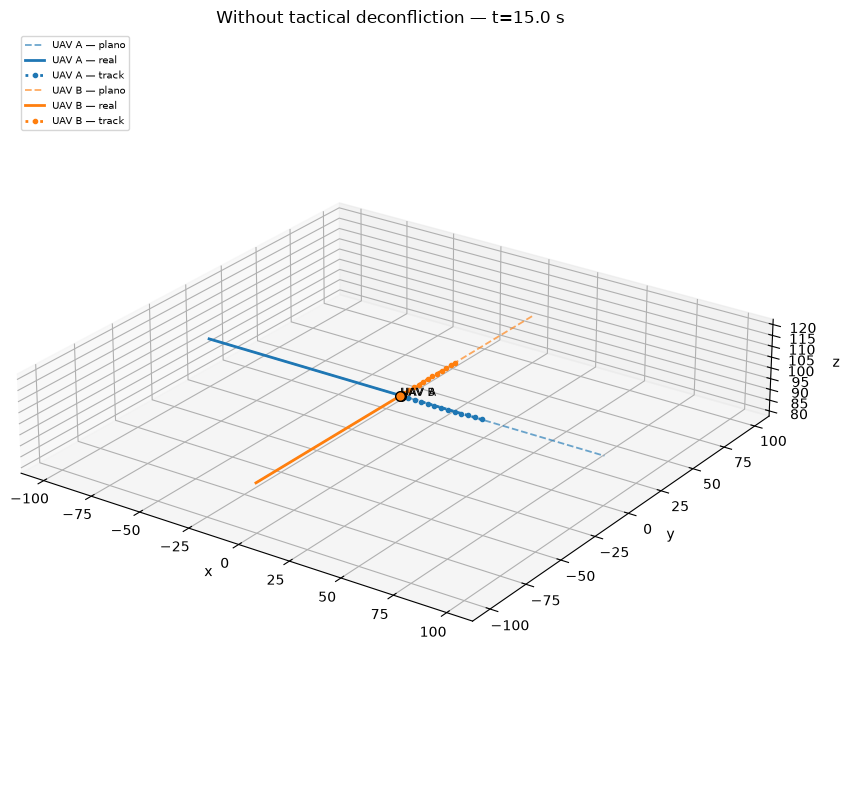

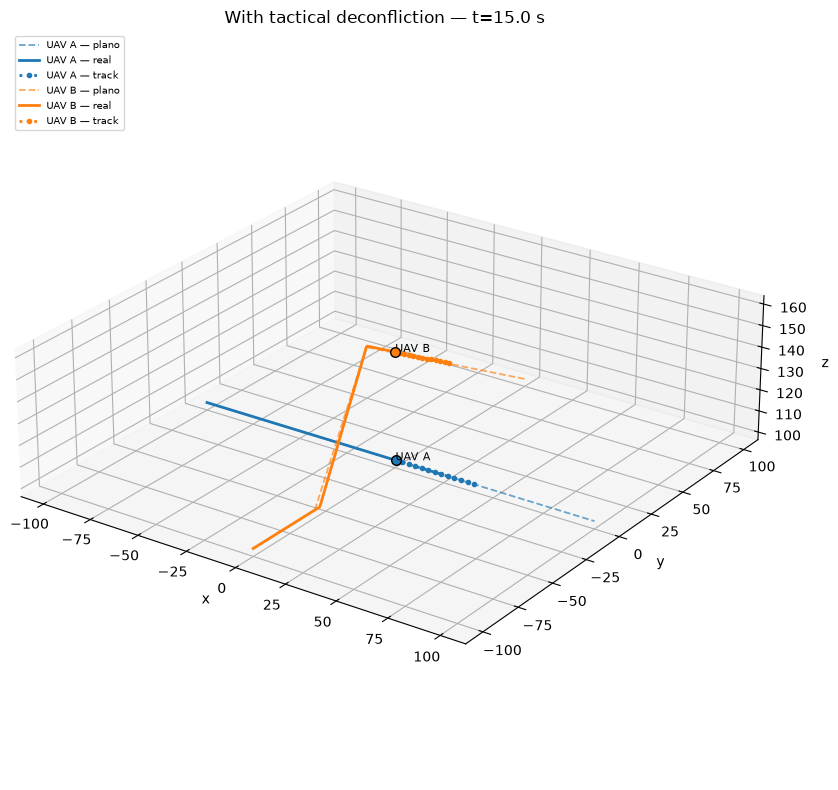

In [5]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV A", "UAV B"),
        view="3d",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=True,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.5,
        figure_size=(10.0, 8.0),
        title=CASES[case_name],
    )

for case_name, dataset_path in dataset_paths.items():
    figure_path = OUTPUT_DIRECTORY / f"{case_name}.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        timestamp=ORIGINAL_ENCOUNTER_TIME,
        output_path=figure_path,
    )
    display(figure)
    print("Saved:", figure_path)

## Animations with tracking

The dotted lines are the current track predictions. In the TD case, UAV B's predicted track changes after the tactical flight-plan update.

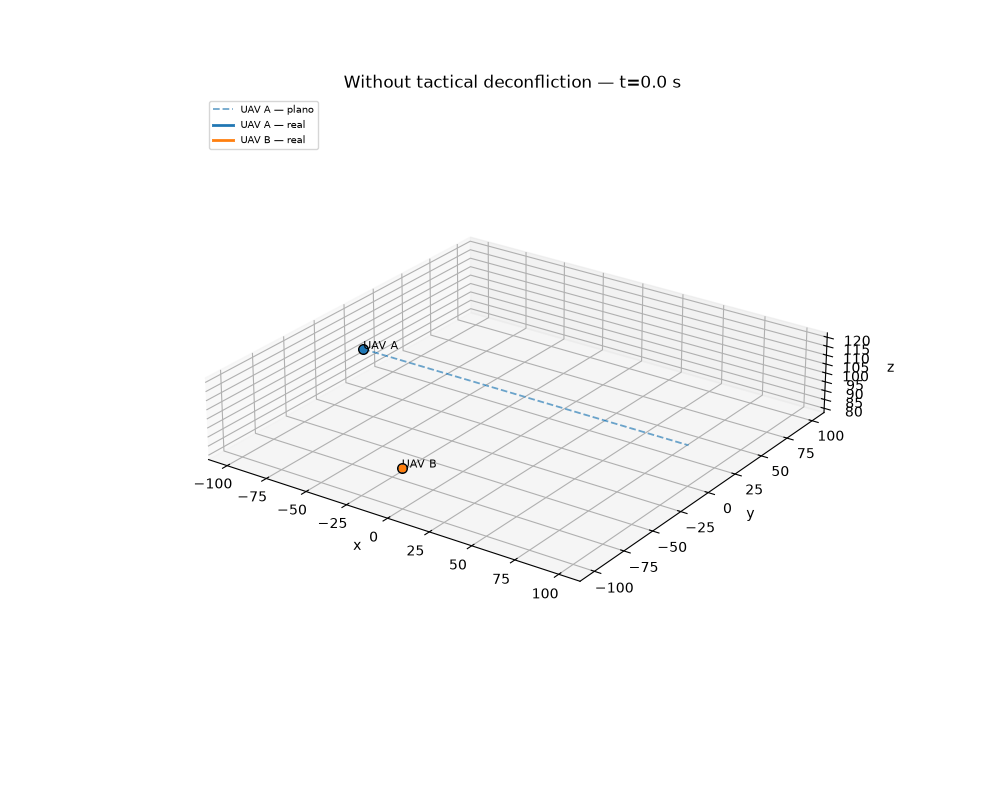

Saved: outputs/output_exp5/without_td.gif


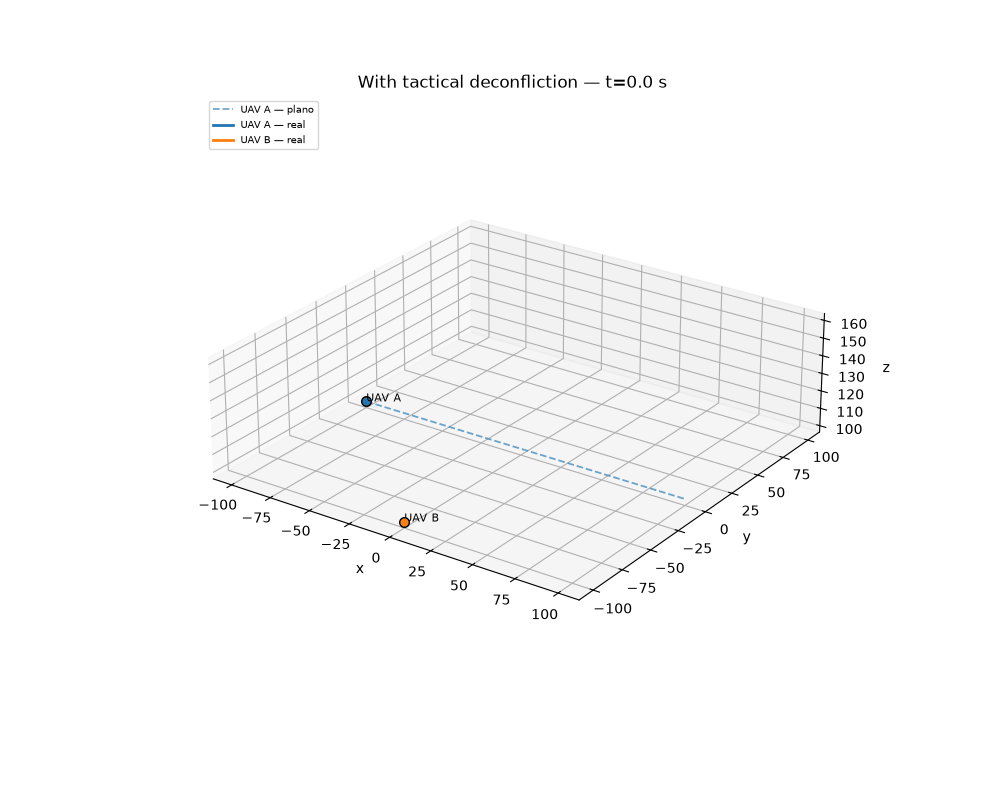

Saved: outputs/output_exp5/with_td.gif


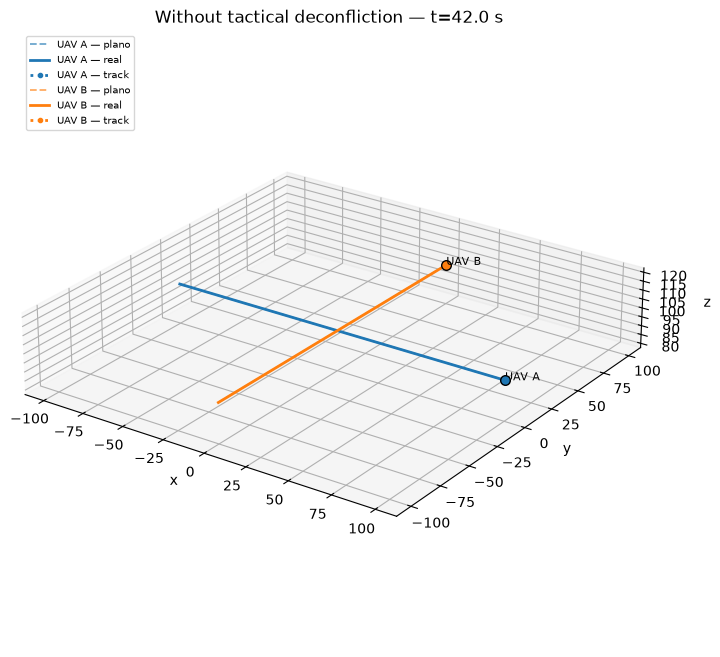

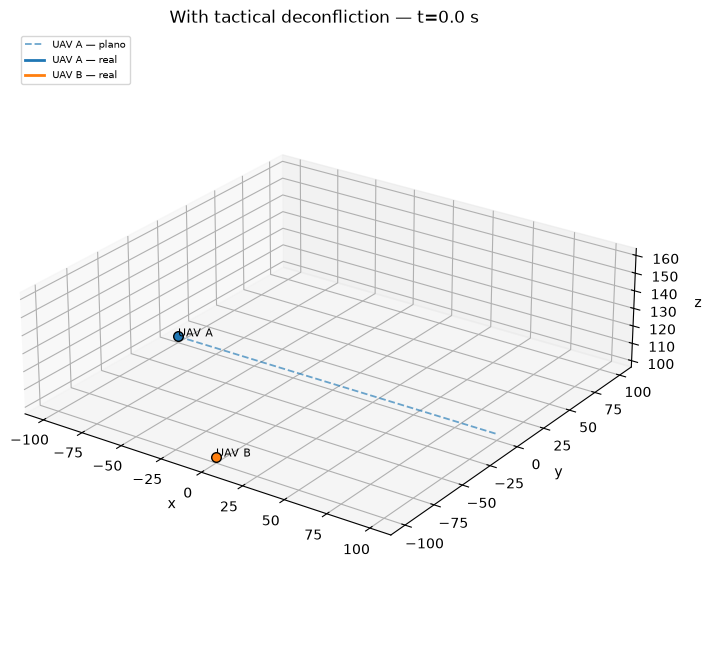

In [6]:
for case_name, dataset_path in dataset_paths.items():
    animation_path = OUTPUT_DIRECTORY / f"{case_name}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        output_path=animation_path,
        fps=6.0,
        dpi=100,
    )
    display(Image(filename=animation_path))
    print("Saved:", animation_path)

## Expected interpretation

Without TD, both UAVs reach the intersection at the same altitude and time. With TD, their predicted tracks reveal the encounter during execution and UAV B receives a vertical flight-plan update, preserving separation while UAV A continues on its original route.